# Unsupervised Learning: Clustering, Dimensionality Reduction, and Anomaly Detection

This companion notebook demonstrates core unsupervised learning algorithms using `scikit-learn`:
1. **Clustering with K-Means**: Partitioning unlabelled data (the Iris dataset) into clusters and comparing clusters to true botanical species.
2. **Dimensionality Reduction with PCA**: Compressing 4-dimensional feature space down to 2 principal components while retaining ~95% of total variance.
3. **Anomaly Detection with Isolation Forest**: Isolating unusual outliers without supervision.
4. **Supervised vs. Unsupervised Learning Comparison**: Contrasting supervised classification against unsupervised pattern discovery.

## 1. Environment Setup and Imports

We configure reproducible random seeds and import the necessary `scikit-learn`, `numpy`, and `matplotlib` modules.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
print("Libraries imported successfully. Random seed set to:", SEED)

Libraries imported successfully. Random seed set to: 42


## 2. Loading and Inspecting the Iris Dataset (Without Labels)

In unsupervised learning, models **never** observe the target labels ($y$). We load the Iris dataset, extract feature matrix $X$, and deliberately discard $y$ during model fitting. We only retain the true labels to verify how well unsupervised discovery recovered the natural groups.

In [2]:
iris = load_iris()
X = iris.data
feature_names = iris.feature_names
y_true = iris.target
target_names = iris.target_names

print(f"Dataset shape: {X.shape[0]} samples, {X.shape[1]} features")
print(f"Feature names: {feature_names}")
print(f"Target species (held out from training): {list(target_names)}")

Dataset shape: 150 samples, 4 features
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target species (held out from training): [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [3]:
# Quick check: dataset properties
assert X.shape == (150, 4), f"Expected shape (150, 4), got {X.shape}"
assert len(np.unique(y_true)) == 3, "Expected 3 true species"
print("Assert passed: Dataset loaded with 150 samples and 4 features.")

Assert passed: Dataset loaded with 150 samples and 4 features.


## 3. Feature Scaling

Distance-based unsupervised algorithms like K-Means and variance-based algorithms like PCA are sensitive to the scale of features. We use `StandardScaler` to normalize each feature to zero mean and unit variance.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature means before scaling:", np.round(X.mean(axis=0), 2))
print("Feature std dev before scaling:", np.round(X.std(axis=0), 2))
print("Feature means after scaling:", np.round(X_scaled.mean(axis=0), 2))
print("Feature std dev after scaling:", np.round(X_scaled.std(axis=0), 2))

Feature means before scaling: [5.84 3.06 3.76 1.2 ]
Feature std dev before scaling: [0.83 0.43 1.76 0.76]
Feature means after scaling: [-0. -0. -0. -0.]
Feature std dev after scaling: [1. 1. 1. 1.]


In [5]:
# Quick check: StandardScaler properties
assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-7), "Means must be approx 0"
assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-7), "Std devs must be approx 1"
print("Assert passed: Features successfully standardized.")

Assert passed: Features successfully standardized.


## 4. Clustering with K-Means

K-Means iteratively finds $k$ centroids and assigns each data point to its nearest centroid to minimize within-cluster inertia (sum-of-squares distance). Here we fit K-Means with $k=3$ clusters.

In [6]:
kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

print("K-Means converged in iterations:", kmeans.n_iter_)
print("Cluster inertia (WCSS):", round(kmeans.inertia_, 2))
print("Cluster center shapes:", kmeans.cluster_centers_.shape)

K-Means converged in iterations:

 4
Cluster inertia (WCSS): 139.82
Cluster center shapes: (3, 4)


### Evaluating Discovered Clusters

We assess the quality of the clusters using:
- **Silhouette Score**: Measures how similar an object is to its own cluster compared to other clusters (range [-1, 1], higher is better; no labels required).
- **Adjusted Rand Index (ARI)**: Measures agreement between discovered clusters and ground truth classes, adjusted for chance (range [-0.5, 1.0], 1.0 is perfect match; uses labels purely for external validation).
- **Cross-tabulation (Contingency Matrix)**: Shows how samples from each true species map onto the discovered cluster IDs.

In [7]:
sil_score = silhouette_score(X_scaled, cluster_labels)
ari_score = adjusted_rand_score(y_true, cluster_labels)

print(f"Silhouette Score (unsupervised): {sil_score:.4f}")
print(f"Adjusted Rand Index (ARI vs ground truth): {ari_score:.4f}")

# Cross-tabulation between true species and cluster labels
print("\nCluster assignment breakdown by true species:")
for cluster_id in range(3):
    in_cluster = (cluster_labels == cluster_id)
    counts = [int(np.sum(in_cluster & (y_true == s))) for s in range(3)]
    print(f"  Cluster {cluster_id}: {counts[0]} Setosa, {counts[1]} Versicolor, {counts[2]} Virginica (Total: {sum(counts)})")

Silhouette Score (unsupervised): 0.4599
Adjusted Rand Index (ARI vs ground truth): 0.6201

Cluster assignment breakdown by true species:
  Cluster 0: 0 Setosa, 39 Versicolor, 14 Virginica (Total: 53)
  Cluster 1: 50 Setosa, 0 Versicolor, 0 Virginica (Total: 50)
  Cluster 2: 0 Setosa, 11 Versicolor, 36 Virginica (Total: 47)


In [8]:
# Quick check: K-Means evaluation thresholds
assert sil_score > 0.40, f"Expected Silhouette score > 0.40, got {sil_score:.4f}"
assert ari_score > 0.60, f"Expected ARI > 0.60, got {ari_score:.4f}"
assert kmeans.n_iter_ < 50, f"Expected convergence in < 50 iterations, got {kmeans.n_iter_}"
print("Assert passed: K-Means formed coherent clusters matching natural species divisions.")

Assert passed: K-Means formed coherent clusters matching natural species divisions.


## 5. Dimensionality Reduction with PCA

Principal Component Analysis (PCA) finds orthogonal directions (principal components) along which the variance of the data is maximized. It projects the 4-dimensional Iris data onto 2 dimensions for visualization and compression.

In [9]:
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
total_variance = np.sum(explained_variance)

print("Explained variance ratio by component:", np.round(explained_variance, 4))
print(f"Total variance retained in 2D: {total_variance * 100:.2f}%")
print(f"PCA reduced shape: {X_pca.shape}")

Explained variance ratio by component: [0.7296 0.2285]
Total variance retained in 2D: 95.81%
PCA reduced shape: (150, 2)


In [10]:
# Quick check: PCA variance
assert X_pca.shape == (150, 2), f"Expected shape (150, 2), got {X_pca.shape}"
assert total_variance > 0.90, f"Expected > 90% variance retained, got {total_variance * 100:.2f}%"
print(f"Assert passed: 2 principal components capture {total_variance * 100:.2f}% of total data variance.")

Assert passed: 2 principal components capture 95.81% of total data variance.


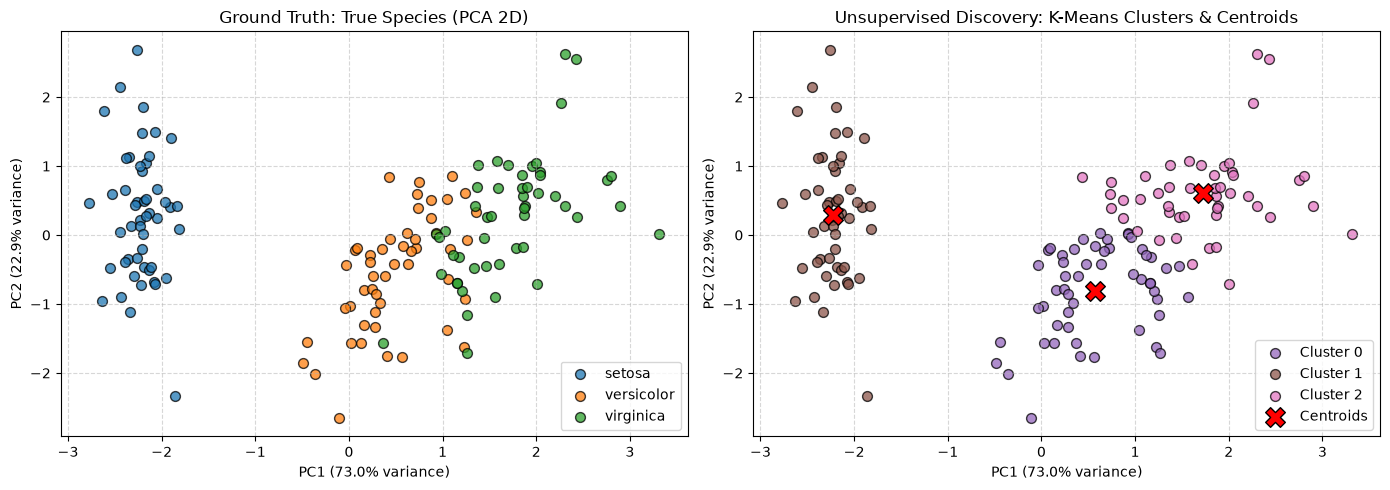

Visualization generated successfully.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: True species in PCA space (ground truth)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for i, target_name in enumerate(target_names):
    axes[0].scatter(
        X_pca[y_true == i, 0],
        X_pca[y_true == i, 1],
        label=target_name,
        color=colors[i],
        alpha=0.75,
        edgecolors='k',
        s=50
    )
axes[0].set_title("Ground Truth: True Species (PCA 2D)")
axes[0].set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
axes[0].set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: K-Means clusters in PCA space (unsupervised discovery)
cluster_colors = ['#9467bd', '#8c564b', '#e377c2']
for c in range(3):
    axes[1].scatter(
        X_pca[cluster_labels == c, 0],
        X_pca[cluster_labels == c, 1],
        label=f"Cluster {c}",
        color=cluster_colors[c],
        alpha=0.75,
        edgecolors='k',
        s=50
    )

# Project centroids onto 2D PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)
axes[1].scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=200,
    color='red',
    edgecolors='black',
    label='Centroids'
)
axes[1].set_title("Unsupervised Discovery: K-Means Clusters & Centroids")
axes[1].set_xlabel(f"PC1 ({explained_variance[0]*100:.1f}% variance)")
axes[1].set_ylabel(f"PC2 ({explained_variance[1]*100:.1f}% variance)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
print("Visualization generated successfully.")

## 6. Anomaly Detection with Isolation Forest

Isolation Forest isolates outliers by randomly selecting a feature and randomly selecting a split value between the minimum and maximum values. Anomalies require fewer random partitions to isolate than normal points because they reside in low-density regions.

In [12]:
# Add 5 synthetic anomalous points to test detection
# Normal standardized points have mean ~0 and std ~1.
# Outliers are points placed far from the distribution (e.g., +4.5 std deviations).
synthetic_anomalies = np.array([
    [4.5, 4.0, 3.8, 4.2],
    [-4.0, -3.5, -4.0, -3.8],
    [5.0, -4.0, 4.5, -3.5],
    [4.2, 3.9, 4.1, 4.0],
    [-3.8, 4.2, -3.9, 3.8]
])

X_augmented = np.vstack([X_scaled, synthetic_anomalies])
contamination_rate = len(synthetic_anomalies) / len(X_augmented)

iso_forest = IsolationForest(contamination=contamination_rate, random_state=SEED)
predictions = iso_forest.fit_predict(X_augmented)
# IsolationForest returns -1 for anomaly, 1 for inlier
detected_anomalies_mask = (predictions == -1)

num_detected = int(np.sum(detected_anomalies_mask))
synthetic_indices = set(range(len(X_scaled), len(X_augmented)))
detected_indices = set(np.where(detected_anomalies_mask)[0])
synthetic_caught = len(synthetic_indices.intersection(detected_indices))

print(f"Total samples with synthetic outliers: {len(X_augmented)}")
print(f"Expected anomalies: {len(synthetic_anomalies)}")
print(f"Total anomalies flagged by Isolation Forest: {num_detected}")
print(f"Synthetic anomalies successfully caught: {synthetic_caught} / {len(synthetic_anomalies)}")

Total samples with synthetic outliers: 155
Expected anomalies: 5
Total anomalies flagged by Isolation Forest: 5
Synthetic anomalies successfully caught: 5 / 5


In [13]:
# Quick check: Isolation Forest detects anomalies
assert num_detected == len(synthetic_anomalies), f"Expected {len(synthetic_anomalies)} anomalies, got {num_detected}"
assert synthetic_caught >= 4, f"Expected at least 4/5 synthetic anomalies caught, got {synthetic_caught}"
print(f"Assert passed: Isolation Forest flagged {num_detected} anomalies ({synthetic_caught}/5 synthetic detected).")

Assert passed: Isolation Forest flagged 5 anomalies (5/5 synthetic detected).


## 7. Comparative Analysis: Supervised vs. Unsupervised Learning

To synthesize our understanding, we directly contrast:
- **Supervised Learning (Logistic Regression)**: Receives $X$ and labels $y$. Optimizes prediction of known classes.
- **Unsupervised Learning (K-Means Clustering)**: Receives only $X$. Discovers cluster structure independently without guidance.

In [14]:
# Split data for supervised baseline
X_tr, X_te, y_tr, y_te = train_test_split(X_scaled, y_true, test_size=0.3, random_state=SEED, stratify=y_true)

# 1. Supervised Model
clf = LogisticRegression(random_state=SEED)
clf.fit(X_tr, y_tr)
supervised_acc = float(clf.score(X_te, y_te))

# 2. Unsupervised Model (evaluated on test split via ARI)
km_test = KMeans(n_clusters=3, random_state=SEED, n_init=10)
km_test_preds = km_test.fit_predict(X_te)
unsupervised_ari = float(adjusted_rand_score(y_te, km_test_preds))

print("=" * 60)
print("PARADIGM COMPARISON: SUPERVISED VS UNSUPERVISED")
print("=" * 60)
print(f"Supervised (Logistic Regression):")
print(f"  Inputs: Features (X) + True Labels (y)")
print(f"  Test Accuracy: {supervised_acc * 100:.1f}%")
print(f"  Model output: Direct probability of Iris-Setosa, Versicolor, Virginica")
print()
print(f"Unsupervised (K-Means Clustering):")
print(f"  Inputs: Features (X) only (no labels provided)")
print(f"  Test Cluster Alignment (ARI): {unsupervised_ari:.4f}")
print(f"  Model output: Discovered Cluster IDs (0, 1, 2) without knowing species names")
print("=" * 60)

PARADIGM COMPARISON: SUPERVISED VS UNSUPERVISED
Supervised (Logistic Regression):
  Inputs: Features (X) + True Labels (y)
  Test Accuracy: 91.1%
  Model output: Direct probability of Iris-Setosa, Versicolor, Virginica

Unsupervised (K-Means Clustering):
  Inputs: Features (X) only (no labels provided)
  Test Cluster Alignment (ARI): 0.5775
  Model output: Discovered Cluster IDs (0, 1, 2) without knowing species names


In [15]:
# Quick check: Supervised vs Unsupervised
assert supervised_acc >= 0.90, "Supervised accuracy should be >= 90%"
assert unsupervised_ari >= 0.50, "Unsupervised test ARI should be >= 0.50"
print("All notebook checks passed successfully!")

All notebook checks passed successfully!
